# 02 — Explore the data

Before training anything, look at the data: do positions actually differ physically, and where do they overlap?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ORDER = ["PG", "SG", "SF", "PF", "C"]

players = pd.read_csv("../data/processed/players.csv")
players.describe().round(1)

,player_id,height_cm,weight_kg,wingspan_cm,reach_cm,body_fat_pct,hand_length_cm,hand_width_cm,ape_index_cm,reach_minus_height_cm,bmi
count,1.680000e+03,1680.0,1680.0,1680.0,1679.0,1236.0,949.0,949.0,1680.0,1679.0,1680.0
mean,1.869973e+06,197.2,97.5,209.2,262.9,7.5,22.2,23.9,12.0,65.7,25.0
std,4.787956e+07,8.5,11.8,10.1,12.3,2.9,1.2,1.8,5.6,5.6,2.0
min,-1.000000e+00,172.1,67.7,177.8,224.8,2.6,19.0,17.8,-5.1,39.4,17.5
25%,1.222280e+04,191.8,89.0,202.6,254.0,5.4,21.6,22.9,8.2,61.6,23.7
50%,2.027360e+05,198.1,96.6,209.6,264.2,6.7,22.2,24.1,12.1,66.0,24.9
75%,1.629610e+06,203.8,105.6,216.5,271.8,8.9,22.9,25.4,15.9,69.8,26.2
max,1.962937e+09,226.7,151.5,249.6,311.2,23.1,26.7,30.5,34.9,84.4,34.5


## Average measurements per position

Height, weight, wingspan and reach should all rise from PG to C.

In [2]:
players.groupby("position").mean(numeric_only=True).reindex(ORDER).round(1)

,player_id,height_cm,weight_kg,wingspan_cm,reach_cm,body_fat_pct,hand_length_cm,hand_width_cm,ape_index_cm,reach_minus_height_cm,bmi
position,,,,,,,,,,,
PG,697450.9,186.0,85.0,196.8,247.3,6.5,21.2,22.9,10.8,61.3,24.6
SG,790289.0,192.9,91.4,204.8,257.0,6.6,21.7,23.6,11.9,64.1,24.6
SF,730572.2,199.1,97.5,210.6,264.9,7.1,22.2,23.9,11.5,65.8,24.6
PF,611871.3,203.3,106.2,216.2,271.6,8.5,22.9,24.6,13.0,68.3,25.7
C,10401668.1,208.9,112.4,221.8,279.7,9.6,23.3,25.4,12.9,70.8,25.8


## Distribution of each feature by position

Each box shows the middle 50% of players, and the line inside it is the median.
**Boxes that overlap** mean those positions are hard to tell apart using that feature alone.

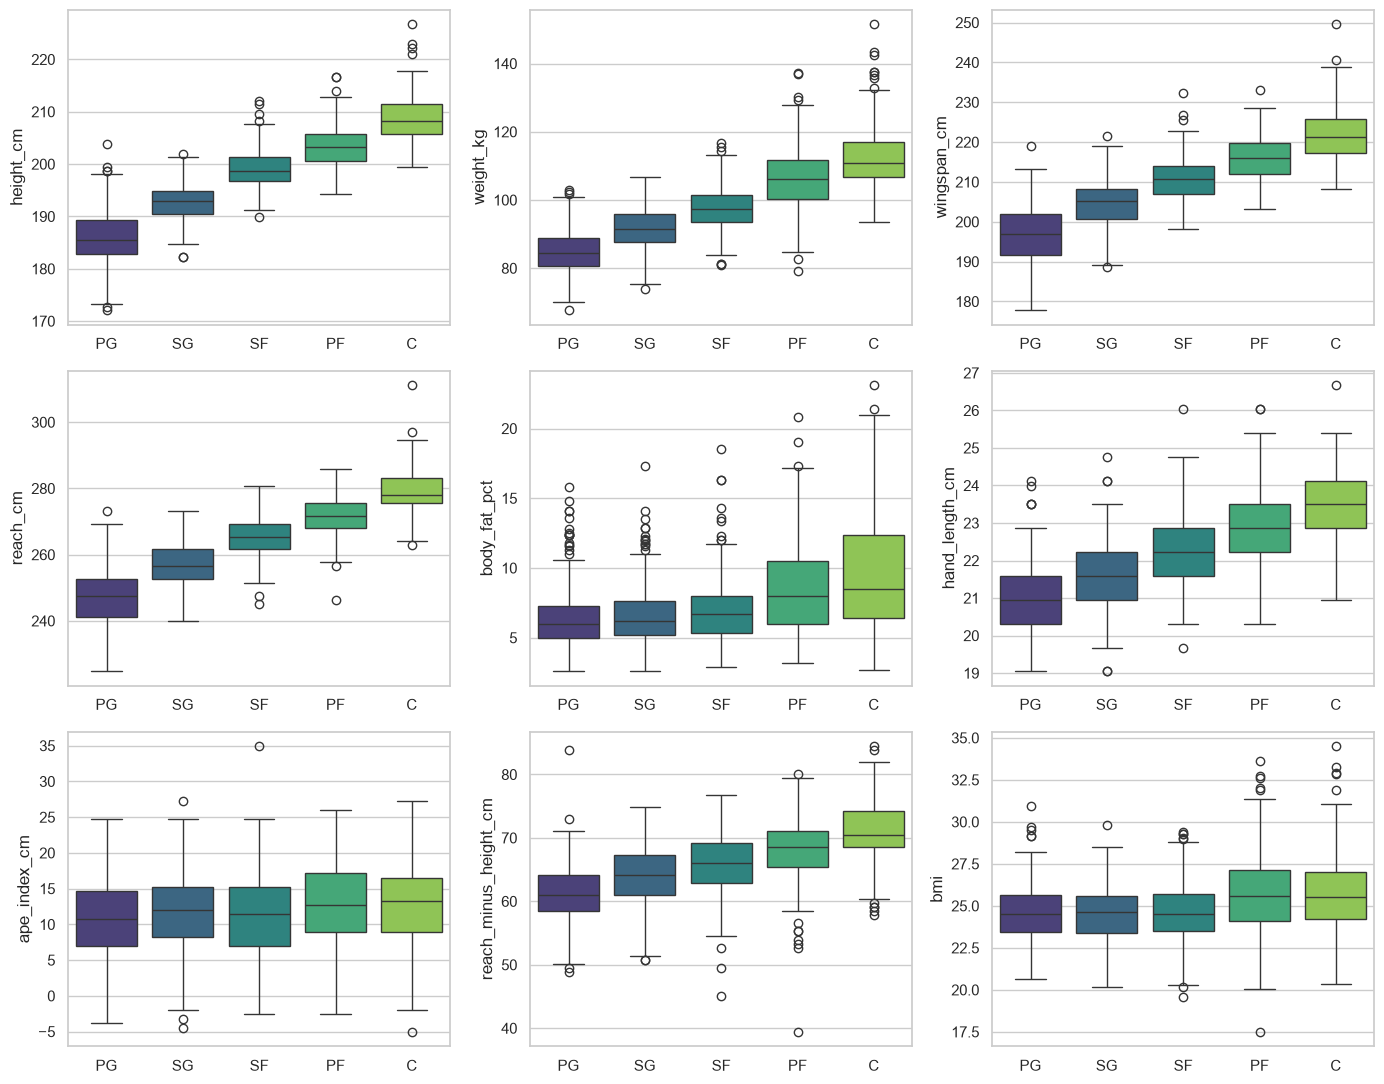

In [3]:
features = ["height_cm", "weight_kg", "wingspan_cm", "reach_cm", "body_fat_pct",
            "hand_length_cm", "ape_index_cm", "reach_minus_height_cm", "bmi"]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, feature in zip(axes.flat, features):
    sns.boxplot(data=players, x="position", y=feature, order=ORDER, hue="position", hue_order=ORDER,
                palette="viridis", legend=False, ax=ax)
    ax.set_xlabel("")
fig.tight_layout()

## How positions overlap (pairplot)

Every dot is a player. Neighbouring positions blend into each other, which is why 100% accuracy is impossible.

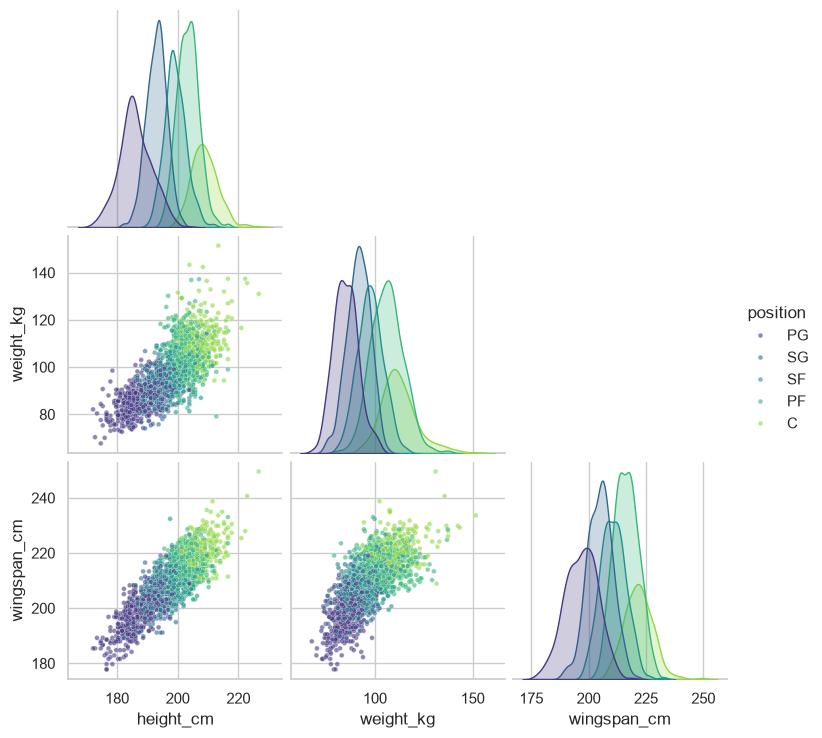

In [4]:
sns.pairplot(players, vars=["height_cm", "weight_kg", "wingspan_cm"], hue="position", hue_order=ORDER,
             palette="viridis", plot_kws={"s": 12, "alpha": 0.6}, corner=True);

## Correlation between features

Values near 1 mean two features carry almost the same information (e.g. height, reach and wingspan).
That's not a problem for most models, but it means adding more "size" features gives diminishing returns.

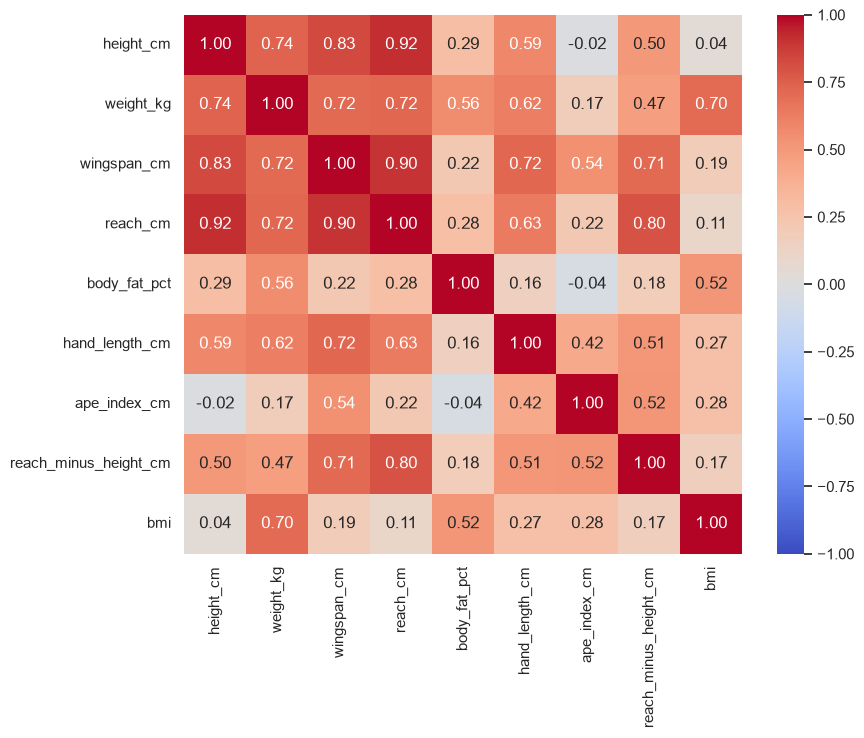

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(players[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1);